In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import os


C:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [ ]:
TRAIN_DIR = r"D:\Rubber final dataset\Training Dataset\Dataset\Rubber_Dataset_SPLIT\train"
VAL_DIR   = r"D:\Rubber final dataset\Training Dataset\Dataset\Rubber_Dataset_SPLIT\val"
TEST_DIR  = r"D:\Rubber final dataset\Training Dataset\Dataset\Rubber_Dataset_SPLIT\test"

IMG_SIZE = 256
BATCH_SIZE = 4   # IMPORTANT for 1GB GPU
EPOCHS = 30
INITIAL_LR = 1e-4
FINE_TUNE_LR = 1e-5


In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print("Classes:", class_names)


Found 3430 files belonging to 7 classes.
Found 611 files belonging to 7 classes.
Found 619 files belonging to 7 classes.
Classes: ['Anthracnose', 'Birds Eye', 'Corynespora Leaf Fall', 'Healthy', 'Leaf Blight', 'Pestalotopsis Leaf Spot', 'Powdery Mildew']


In [5]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)


In [9]:
from tensorflow.keras.applications.efficientnet import preprocess_input

base_model = EfficientNetB0(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = preprocess_input(inputs)   # IMPORTANT FIX

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),  # increase LR initially
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [7]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=6,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=3
    )
]


In [10]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)


Epoch 1/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 171s 180ms/step - accuracy: 0.8227 - loss: 0.6239 - val_accuracy: 0.9444 - val_loss: 0.2453
Epoch 2/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 146s 170ms/step - accuracy: 0.9327 - loss: 0.2470 - val_accuracy: 0.9656 - val_loss: 0.1526
Epoch 3/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 149s 173ms/step - accuracy: 0.9571 - loss: 0.1711 - val_accuracy: 0.9705 - val_loss: 0.1148
Epoch 4/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 153s 178ms/step - accuracy: 0.9659 - loss: 0.1284 - val_accuracy: 0.9738 - val_loss: 0.0925
Epoch 5/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 151s 175ms/step - accuracy: 0.9706 - loss: 0.1117 - val_accuracy: 0.9787 - val_loss: 0.0791
Epoch 6/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 151s 176ms/step - accuracy: 0.9714 - loss: 0.0998 - val_accuracy: 0.9804 - val_loss: 0.0778
Epoch 7/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 149s 174ms/step - accuracy: 0.9758 - loss: 0.0915 - val_accuracy: 0.9771 - val_loss: 0.0671
Epoch 8/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 151s 176ms/step - accuracy: 0.9735 -

In [11]:
base_model.trainable = True

for layer in base_model.layers[:-25]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)


Epoch 1/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 198s 205ms/step - accuracy: 0.8009 - loss: 0.5958 - val_accuracy: 0.9624 - val_loss: 0.1179
Epoch 2/5
858/858 ━━━━━━━━━━━━━━━━━━━━ 175s 204ms/step - accuracy: 0.8487 - loss: 0.4416 - val_accuracy: 0.9705 - val_loss: 0.0898
Epoch 3/5
227/858 ━━━━━━━━━━━━━━━━━━━━ 2:34 244ms/step - accuracy: 0.8784 - loss: 0.3880

KeyboardInterrupt: 

In [12]:
test_loss, test_acc = model.evaluate(test_ds)
print("Final Test Accuracy:", test_acc)


155/155 ━━━━━━━━━━━━━━━━━━━━ 22s 139ms/step - accuracy: 0.9774 - loss: 0.0754
Final Test Accuracy: 0.9773828983306885


In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


In [14]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)

    y_pred.extend(predicted_classes)
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total Test Samples:", len(y_true))


Total Test Samples: 619


In [15]:
accuracy = accuracy_score(y_true, y_pred)
precision_macro = precision_score(y_true, y_pred, average='macro')
recall_macro = recall_score(y_true, y_pred, average='macro')
f1_macro = f1_score(y_true, y_pred, average='macro')

precision_weighted = precision_score(y_true, y_pred, average='weighted')
recall_weighted = recall_score(y_true, y_pred, average='weighted')
f1_weighted = f1_score(y_true, y_pred, average='weighted')

print("Overall Accuracy:", round(accuracy, 4))
print("Macro Precision:", round(precision_macro, 4))
print("Macro Recall:", round(recall_macro, 4))
print("Macro F1-score:", round(f1_macro, 4))

print("\nWeighted Precision:", round(precision_weighted, 4))
print("Weighted Recall:", round(recall_weighted, 4))
print("Weighted F1-score:", round(f1_weighted, 4))


Overall Accuracy: 0.9774
Macro Precision: 0.9781
Macro Recall: 0.9747
Macro F1-score: 0.9761

Weighted Precision: 0.9778
Weighted Recall: 0.9774
Weighted F1-score: 0.9774


In [16]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

print(report_df)

# Save to CSV for journal submission
report_df.to_csv("classification_report.csv")


                         precision    recall  f1-score     support
Anthracnose               0.962264  0.962264  0.962264  106.000000
Birds Eye                 0.990291  0.962264  0.976077  106.000000
Corynespora Leaf Fall     0.974359  0.974359  0.974359   78.000000
Healthy                   1.000000  1.000000  1.000000  106.000000
Leaf Blight               0.972222  0.990566  0.981308  106.000000
Pestalotopsis Leaf Spot   1.000000  0.933333  0.965517   45.000000
Powdery Mildew            0.947368  1.000000  0.972973   72.000000
accuracy                  0.977383  0.977383  0.977383    0.977383
macro avg                 0.978072  0.974684  0.976071  619.000000
weighted avg              0.977766  0.977383  0.977359  619.000000


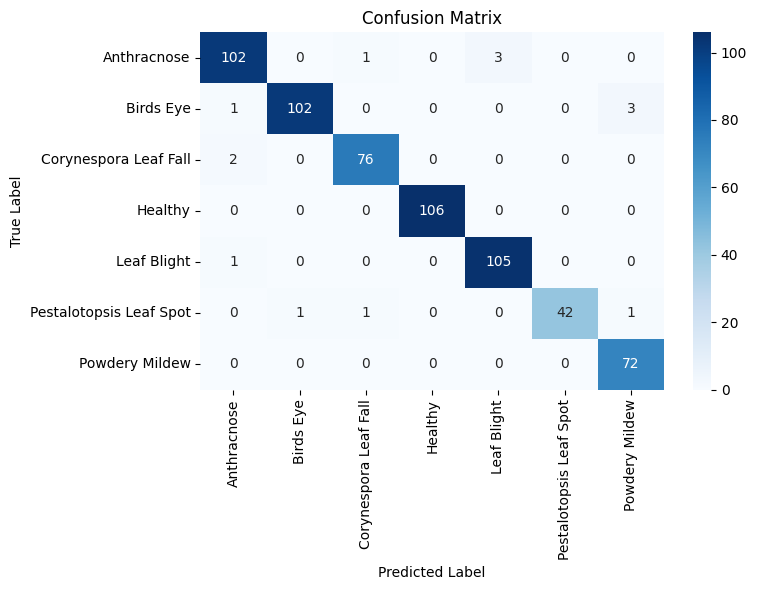

In [17]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


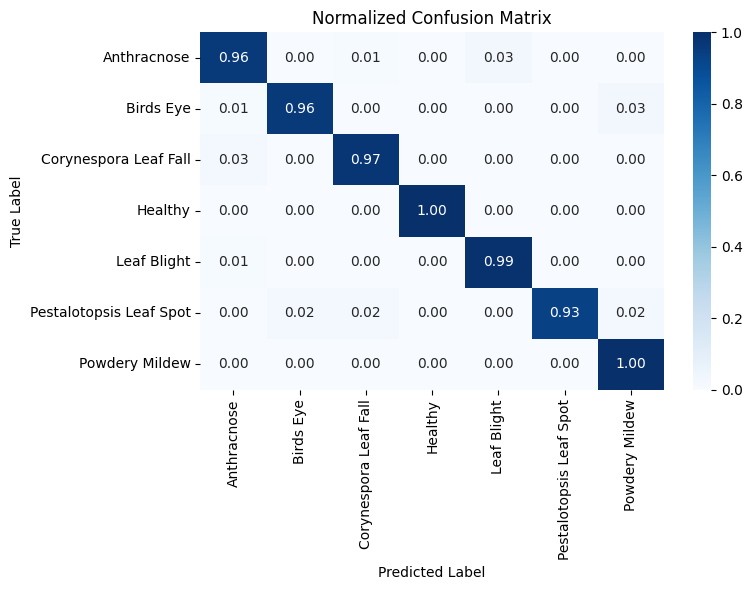

In [18]:
cm_normalized = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(8,6))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Normalized Confusion Matrix")
plt.tight_layout()
plt.show()


In [19]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open("rubber_model.tflite", "wb") as f:
    f.write(tflite_model)

print("TFLite model saved successfully.")


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpfla417vy\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpfla417vy\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmpfla417vy'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='keras_tensor_482')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  2598117065552: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2598117065168: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2598113433296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2598113432912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2598113433680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2598113434640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2598113435216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2598113434064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2598113433872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2598113435024: TensorSpec(shape=(), dtype=tf.resou

In [22]:
model.save("rubber_model.h5")


In [23]:
model.save("rubber_model.keras")


In [24]:
import json

with open("training_history.json", "w") as f:
    json.dump(history.history, f)


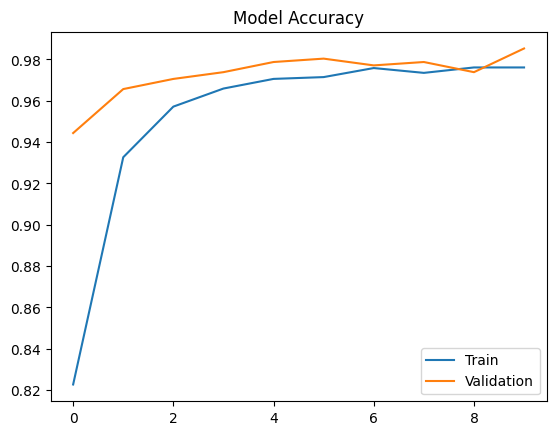

In [25]:
import json
import matplotlib.pyplot as plt

with open("training_history.json", "r") as f:
    history = json.load(f)

plt.plot(history["accuracy"])
plt.plot(history["val_accuracy"])
plt.title("Model Accuracy")
plt.legend(["Train", "Validation"])
plt.show()


In [1]:
import tensorflow as tf
from tensorflow.keras.applications.efficientnet import preprocess_input
import numpy as np

x = np.array([0., 127.5, 255.0])
print(preprocess_input(x))
# checking comptablity with flutter

C:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


[  0.  127.5 255. ]


In [ ]:
import tensorflow as tf
import numpy as np
import time


model_path = r"D:\Rubber final dataset\Training Dataset\rubber_model.tflite"

interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()

input_details  = interpreter.get_input_details()
output_details = interpreter.get_output_details()


print(f"Input shape  : {input_details[0]['shape']}")
print(f"Input dtype  : {input_details[0]['dtype']}")
print(f"Output shape : {output_details[0]['shape']}")

input_shape = input_details[0]['shape']
input_dtype = input_details[0]['dtype']

dummy_input = np.random.randint(
    0, 256,
    size=input_shape,
    dtype=np.uint8
).astype(input_dtype)

print(f"\nDummy input shape: {dummy_input.shape}")


print("")
for _ in range(3):
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
print("")


times = []

for i in range(50):
    start = time.perf_counter()
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
    interpreter.get_tensor(output_details[0]['index'])
    end = time.perf_counter()
    times.append((end - start) * 1000)



print(f"Average latency : {np.mean(times):.2f} ms")
print(f"Std deviation   : {np.std(times):.2f} ms")
print(f"Min latency     : {np.min(times):.2f} ms")
print(f"Max latency     : {np.max(times):.2f} ms")
print(f"Median latency  : {np.median(times):.2f} ms")


Input shape  : [  1 256 256   3]
Input dtype  : <class 'numpy.float32'>
Output shape : [1 7]

Dummy input shape: (1, 256, 256, 3)




In [4]:
import tensorflow as tf
import os

# 1. Load your trained Keras model
model = tf.keras.models.load_model(r"D:\Rubber final dataset\Training Dataset\rubber_model.keras")
print("Model loaded successfully")

# 2. Convert to Float TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# 3. Save the model
float_path = r"D:\Rubber final dataset\Training Dataset\rubber_model_float.tflite"

with open(float_path, "wb") as f:
    f.write(tflite_model)

print("\nFloat TFLite saved:", float_path)
print("Size:", round(os.path.getsize(float_path) / (1024 * 1024), 2), "MB")

INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmphvkncapv\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmphvkncapv\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmphvkncapv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  2351955791888: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2351955788816: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2351910793488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2351910793680: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2351910795792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2351910795408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2351910796176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2351910795600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2351910796944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2351910796752: TensorSpec(shape=(), dtype=tf.resource

In [6]:
import tensorflow as tf
import numpy as np
import os

# 1. Load the trained Keras model
model = tf.keras.models.load_model(r"D:\Rubber final dataset\Training Dataset\rubber_model.keras")
print("Model loaded successfully")

# 2. Re-create the training dataset (needed for representative data)
TRAIN_DIR = r"D:\Rubber final dataset\Training Dataset\Dataset\Rubber_Dataset_SPLIT\train"
IMG_SIZE = 256
BATCH_SIZE = 4

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE
)

# 3. INT8 Quantization
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]

def representative_dataset():
    for images, _ in train_ds.take(80):          # 80 batches is enough
        for img in images:
            img = tf.expand_dims(img, axis=0)
            yield [img]

converter.representative_dataset = representative_dataset

# Force full integer (INT8) quantization
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8

# Convert
print("Converting to INT8... this may take 1–3 minutes")
int8_tflite_model = converter.convert()

# 4. Save the model
int8_path = r"D:\Rubber final dataset\Training Dataset\rubber_model_INT8.tflite"
with open(int8_path, "wb") as f:
    f.write(int8_tflite_model)

print("\nINT8 model saved successfully!")
print("Path:", int8_path)
print("Size:", round(os.path.getsize(int8_path) / (1024 * 1024), 2), "MB")

Model loaded successfully
Found 3430 files belonging to 7 classes.


C:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 27 variables whereas the saved optimizer has 52 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Converting to INT8... this may take 1–3 minutes
INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpobpum4f3\assets


INFO:tensorflow:Assets written to: C:\Users\lenovo\AppData\Local\Temp\tmpobpum4f3\assets


Saved artifact at 'C:\Users\lenovo\AppData\Local\Temp\tmpobpum4f3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 7), dtype=tf.float32, name=None)
Captures:
  2352548742160: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2352548742928: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  2352509712528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352509713296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352509711760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352509713872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352509712720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352509714256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352509711568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2352511533520: TensorSpec(shape=(), dtype=tf.resource

C:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\lite\python\convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(



INT8 model saved successfully!
Path: D:\Rubber final dataset\Training Dataset\rubber_model_INT8.tflite
Size: 4.69 MB


In [7]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import os

# ====================== 1. Load INT8 model ======================
int8_path = r"D:\Rubber final dataset\Training Dataset\rubber_model_INT8.tflite"

interpreter = tf.lite.Interpreter(model_path=int8_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Input details :", input_details[0])
print("Output details:", output_details[0])
print("Input dtype   :", input_details[0]['dtype'])
print("Output dtype  :", output_details[0]['dtype'])


TEST_DIR = r"D:\Rubber final dataset\Training Dataset\Dataset\Rubber_Dataset_SPLIT\test"
IMG_SIZE = 256
BATCH_SIZE = 1          # important for TFLite evaluation

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = test_ds.class_names
print("Classes:", class_names)

# ====================== 3. Run Inference ======================
y_true = []
y_pred = []

print("\nEvaluating INT8 model on test set... Please wait")

for images, labels in test_ds:
    # images shape: (1, 256, 256, 3), values in 0–255 (float32)
    
    # Prepare input according to model requirement
    if input_details[0]['dtype'] == np.uint8:
        input_data = images.numpy().astype(np.uint8)
    else:
        input_data = images.numpy().astype(np.float32)

    # Run inference
    interpreter.set_tensor(input_details[0]['index'], input_data)
    interpreter.invoke()
    
    output = interpreter.get_tensor(output_details[0]['index'])
    
    # Get prediction
    pred_class = np.argmax(output[0])
    
    y_true.append(labels.numpy()[0])
    y_pred.append(pred_class)

# ====================== 4. Calculate Results ======================
acc = accuracy_score(y_true, y_pred)
print("\n" + "="*50)
print(f"INT8 Test Accuracy: {acc*100:.2f}%")
print("="*50)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Input details : {'name': 'serving_default_input_layer_3:0', 'index': 0, 'shape': array([  1, 256, 256,   3], dtype=int32), 'shape_signature': array([ -1, 256, 256,   3], dtype=int32), 'dtype': <class 'numpy.uint8'>, 'quantization': (1.0, 0), 'quantization_parameters': {'scales': array([1.], dtype=float32), 'zero_points': array([0], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}
Output details: {'name': 'StatefulPartitionedCall_1:0', 'index': 488, 'shape': array([1, 7], dtype=int32), 'shape_signature': array([-1,  7], dtype=int32), 'dtype': <class 'numpy.uint8'>, 'quantization': (0.00390625, 0), 'quantization_parameters': {'scales': array([0.00390625], dtype=float32), 'zero_points': array([0], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}
Input dtype   : <class 'numpy.uint8'>
Output dtype  : <class 'numpy.uint8'>
Found 619 files belonging to 7 classes.


C:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Classes: ['Anthracnose', 'Birds Eye', 'Corynespora Leaf Fall', 'Healthy', 'Leaf Blight', 'Pestalotopsis Leaf Spot', 'Powdery Mildew']

Evaluating INT8 model on test set... Please wait

INT8 Test Accuracy: 86.91%

Classification Report:
                         precision    recall  f1-score   support

            Anthracnose     0.8889    0.6792    0.7701       106
              Birds Eye     0.9767    0.7925    0.8750       106
  Corynespora Leaf Fall     0.8987    0.9103    0.9045        78
                Healthy     0.9802    0.9340    0.9565       106
            Leaf Blight     0.9043    0.9811    0.9412       106
Pestalotopsis Leaf Spot     0.5000    0.9333    0.6512        45
         Powdery Mildew     0.9041    0.9167    0.9103        72

               accuracy                         0.8691       619
              macro avg     0.8647    0.8781    0.8584       619
           weighted avg     0.8970    0.8691    0.8739       619


Confusion Matrix:
[[ 72   0   3   0   8  23  

In [1]:
print ("new int8 quantization")

new int8 quantization
